## Praktikum D1 – Regresi dari Citra Sintetis (Prediksi Radius Lingkaran)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras import layers, models

# Generator 1 sample
def make_sample(img_size=64, min_r=5, max_r=20):
    # Membuat radius secara acak
    r = np.random.randint(min_r, max_r + 1)

    # Membuat background hitam
    img = np.zeros((img_size, img_size), dtype=np.uint8)

    # Membuat posisi pusat lingkaran secara acak
    cx = np.random.randint(r, img_size - r)
    cy = np.random.randint(r, img_size - r)

    # Menggambar lingkaran putih
    cv2.circle(img, (cx, cy), r, (255,), -1)

    # Normalisasi pixel menjadi 0-1
    img = (img / 255.0).astype(np.float32)

    # Mengubah grayscale menjadi 3 channel
    img3 = np.stack([img, img, img], axis=-1)

    return img3, float(r), (cx, cy)

Jumlah gambar: 24


In [ ]:
N_show = 24

samples = [make_sample() for _ in range(N_show)]

imgs = [s[0] for s in samples]
rads = [s[1] for s in samples]
centers = [s[2] for s in samples]

print("Jumlah gambar:", len(imgs))

Jumlah gambar: 24


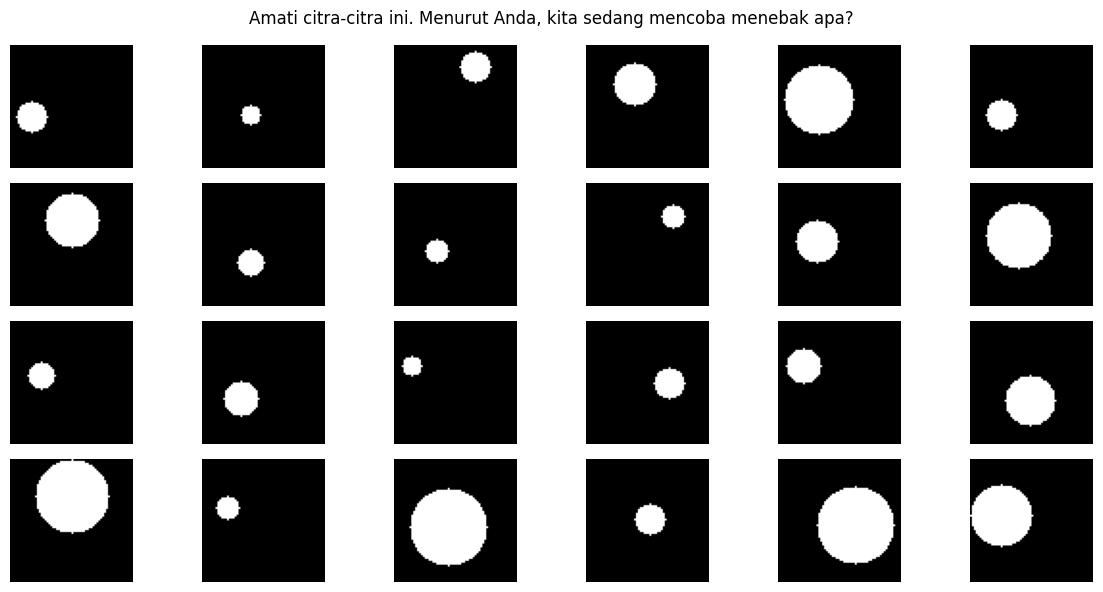

In [ ]:
cols = 6
rows = N_show // cols

plt.figure(figsize=(12, 6))

for i in range(N_show):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(imgs[i].squeeze(), cmap='gray')
    plt.axis('off')

plt.suptitle(
    "Amati citra-citra ini. Menurut Anda, kita sedang mencoba menebak apa?"
)

plt.tight_layout()
plt.show()

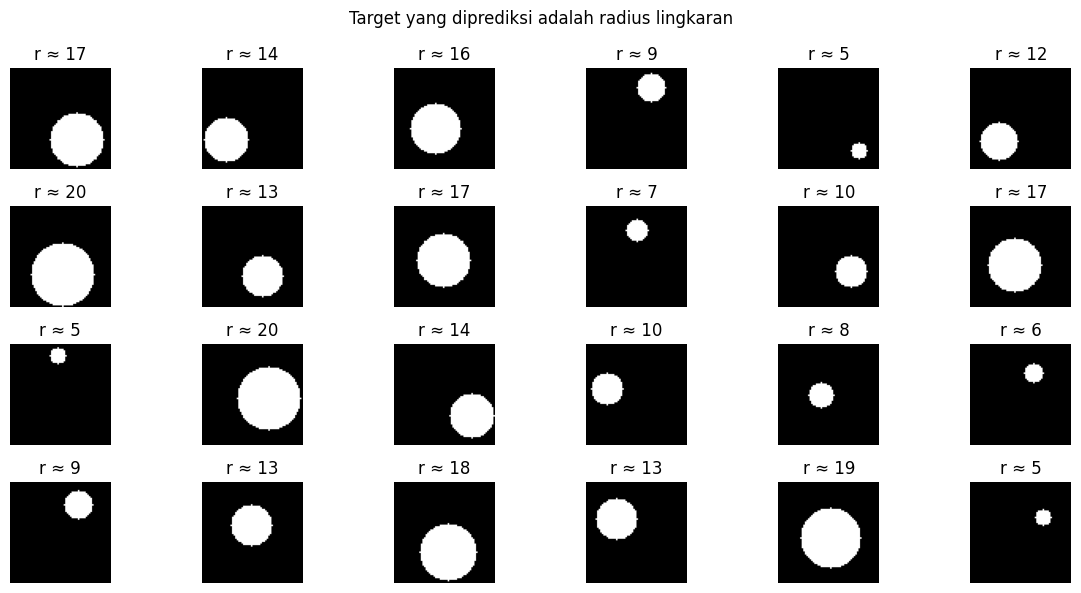

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(N_show):
    plt.subplot(rows, cols, i + 1)

    plt.imshow(imgs[i].squeeze(), cmap='gray')
    plt.title(f"r ≈ {int(rads[i])}")
    plt.axis('off')

plt.suptitle(
    "Target yang diprediksi adalah radius lingkaran"
)

plt.tight_layout()
plt.show()

In [ ]:
N = 3000

X, y, C = zip(*[make_sample() for _ in range(N)])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)

Xtr, Xte, ytr, yte = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X training :", Xtr.shape)
print("X testing  :", Xte.shape)
print("y training :", ytr.shape)
print("y testing  :", yte.shape)

X training : (2400, 64, 64, 3)
X testing  : (600, 64, 64, 3)
y training : (2400,)
y testing  : (600,)


In [ ]:
model_d1 = models.Sequential([
    layers.Input((64, 64, 3)),

    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation='relu'),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation='relu'),

    # Output regresi
    layers.Dense(1)
])

model_d1.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model_d1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_d1 = model_d1.fit(
    Xtr,
    ytr,
    validation_data=(Xte, yte),
    epochs=12,
    batch_size=64,
    verbose=1
)

Epoch 1/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 8s 79ms/step - loss: 40.3502 - mae: 4.6028 - val_loss: 3.3119 - val_mae: 1.4471
Epoch 2/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 2.5741 - mae: 1.2709 - val_loss: 1.5659 - val_mae: 1.0014
Epoch 3/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.6688 - mae: 1.0694 - val_loss: 1.4583 - val_mae: 0.9865
Epoch 4/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 1.6169 - mae: 1.0502 - val_loss: 1.4392 - val_mae: 0.9803
Epoch 5/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.6142 - mae: 1.0462 - val_loss: 1.6182 - val_mae: 1.0731
Epoch 6/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.5742 - mae: 1.0338 - val_loss: 1.4410 - val_mae: 1.0024
Epoch 7/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.5343 - mae: 1.0240 - val_loss: 1.4298 - val_mae: 0.9983
Epoch 8/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.5210 - mae: 1.0186 - val_loss: 1.3755 - val_mae: 0.9453
Epoch 9/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.50

In [ ]:
y_pred_d1 = model_d1.predict(Xte).ravel()

mae_d1 = mean_absolute_error(yte, y_pred_d1)

rmse_d1 = float(
    np.sqrt(np.mean((yte - y_pred_d1) ** 2))
)

r2_d1 = r2_score(yte, y_pred_d1)

print(f"MAE  = {mae_d1:.3f}")
print(f"RMSE = {rmse_d1:.3f}")
print(f"R²   = {r2_d1:.3f}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step
MAE  = 0.938
RMSE = 1.144
R²   = 0.939


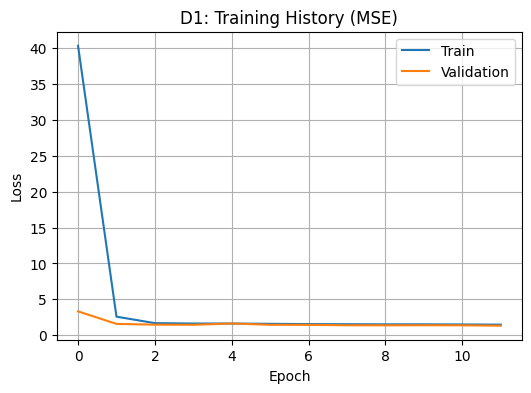

In [ ]:
plt.figure(figsize=(6, 4))

plt.plot(
    history_d1.history['loss'],
    label='Train'
)

plt.plot(
    history_d1.history['val_loss'],
    label='Validation'
)

plt.title("D1: Training History (MSE)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

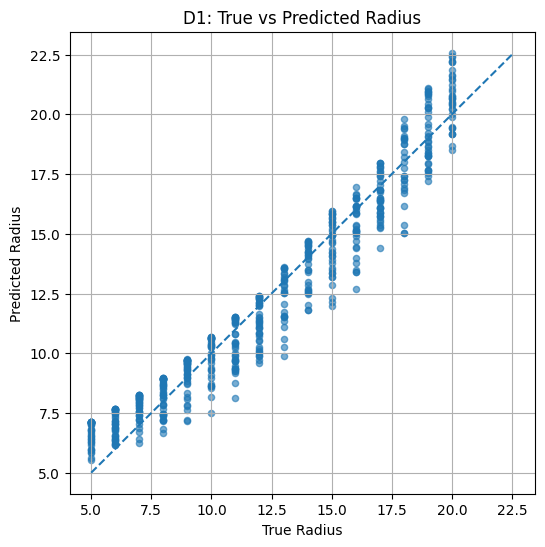

In [ ]:
plt.figure(figsize=(6, 6))

plt.scatter(
    yte,
    y_pred_d1,
    s=20,
    alpha=0.6
)

lims = [
    min(yte.min(), y_pred_d1.min()),
    max(yte.max(), y_pred_d1.max())
]

plt.plot(
    lims,
    lims,
    '--'
)

plt.xlabel("True Radius")
plt.ylabel("Predicted Radius")
plt.title("D1: True vs Predicted Radius")

plt.grid(True)
plt.show()

## D2 Prediksi Umur UTKFace

In [ ]:
import os
import subprocess
import sys

!pip -q install -U kaggle

os.environ["KAGGLE_API_TOKEN"] = "KGAT_b93a6e52350957fd4b9865999f0a6fda"

print("Kaggle CLI berhasil diinstall.")
print("Token Kaggle sudah diset.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 11.8 MB/s eta 0:00:00
Kaggle CLI berhasil diinstall.
Token Kaggle sudah diset.


In [ ]:
!kaggle datasets download -d jangedoo/utkface-new -p /content -q

Dataset URL: https://www.kaggle.com/datasets/jangedoo/utkface-new
License(s): copyright-authors


In [ ]:
!unzip -q /content/utkface-new.zip -d /content/utk

print("Dataset UTKFace berhasil diekstrak.")

Dataset UTKFace berhasil diekstrak.


In [ ]:
import matplotlib.pyplot as plt
import os
import glob

from PIL import Image

files_utk = glob.glob("/content/utk/UTKFace/*.jpg")

files_utk = sorted(files_utk)

print(f"Total gambar ditemukan: {len(files_utk)}")

Total gambar ditemukan: 23708


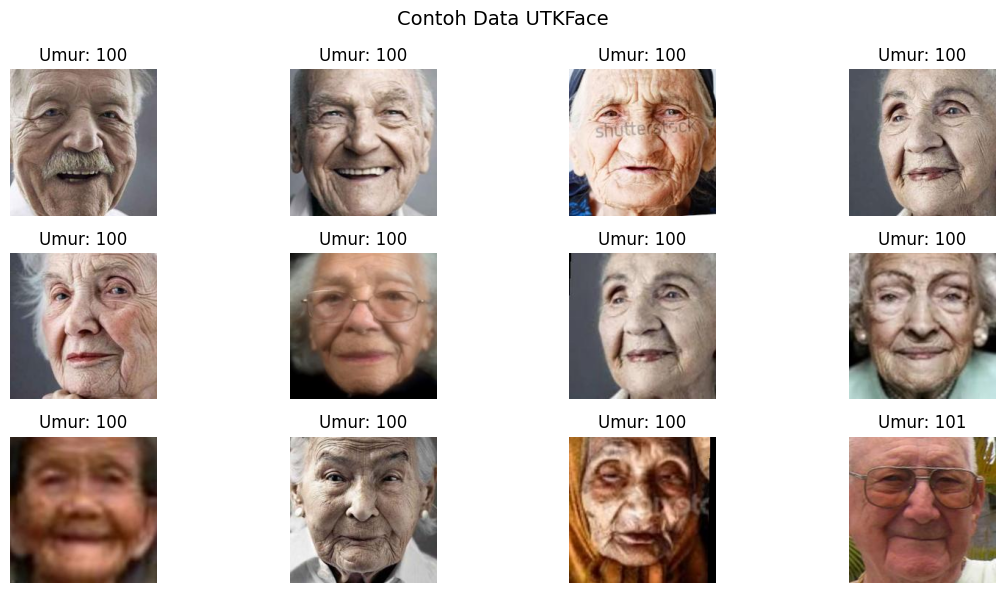

In [ ]:
plt.figure(figsize=(12, 6))

for i, f in enumerate(files_utk[:12]):

    age = int(
        os.path.basename(f).split("_")[0]
    )

    img = Image.open(f)

    plt.subplot(3, 4, i + 1)

    plt.imshow(img)
    plt.title(f"Umur: {age}")
    plt.axis("off")

plt.suptitle(
    "Contoh Data UTKFace",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
import numpy as np

from sklearn.model_selection import train_test_split

def parse_age_from_name(fp):
    return int(
        os.path.basename(fp).split('_')[0]
    )

ages = np.array(
    [parse_age_from_name(f) for f in files_utk],
    dtype=np.float32
)

train_files, test_files, y_train, y_test = train_test_split(
    files_utk,
    ages,
    test_size=0.2,
    random_state=42
)

print("Training:", len(train_files))
print("Testing :", len(test_files))

Training: 18966
Testing : 4742


In [ ]:
IMG_SIZE = 160

def load_img(fp, label):

    img = tf.io.read_file(fp)

    img = tf.image.decode_jpeg(
        img,
        channels=3
    )

    img = tf.image.resize(
        img,
        (IMG_SIZE, IMG_SIZE)
    )

    img = img / 255.0

    return img, label

In [ ]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_files, y_train)
).map(
    load_img
).batch(64)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_files, y_test)
).map(
    load_img
).batch(64)

print("Dataset siap dilatih.")

Dataset siap dilatih.


In [ ]:
from tensorflow.keras import layers, models
from sklearn.metrics import mean_absolute_error, r2_score

print(
    "Hardware:",
    "GPU"
    if tf.config.list_physical_devices('GPU')
    else "CPU"
)

Hardware: GPU


In [ ]:
base_model_d2 = tf.keras.applications.MobileNetV2(
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    weights='imagenet'
)

base_model_d2.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
inputs = tf.keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3)
)

x = tf.keras.applications.mobilenet_v2.preprocess_input(
    inputs * 255.0
)

x = base_model_d2(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.2)(x)

x = layers.Dense(
    128,
    activation='relu'
)(x)

outputs = layers.Dense(1)(x)

model_d2 = tf.keras.Model(
    inputs,
    outputs
)

In [ ]:
model_d2.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='mse',
    metrics=['mae']
)

model_d2.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply_1 (Multiply)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
callbacks_d2 = [

    tf.keras.callbacks.EarlyStopping(
        patience=3,
        restore_best_weights=True,
        monitor='val_loss'
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        patience=2,
        factor=0.5,
        min_lr=1e-5,
        monitor='val_loss'
    )
]

In [ ]:
history_d2 = model_d2.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10,
    callbacks=callbacks_d2,
    verbose=1
)

Epoch 1/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 36s 90ms/step - loss: 224.5010 - mae: 11.1417 - val_loss: 159.1848 - val_mae: 9.5918 - learning_rate: 0.0010
Epoch 2/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 14s 48ms/step - loss: 152.1181 - mae: 9.1816 - val_loss: 147.3616 - val_mae: 9.1439 - learning_rate: 0.0010
Epoch 3/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 48ms/step - loss: 142.4993 - mae: 8.8166 - val_loss: 143.6875 - val_mae: 9.0042 - learning_rate: 0.0010
Epoch 4/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 14s 48ms/step - loss: 138.6315 - mae: 8.6681 - val_loss: 138.6707 - val_mae: 8.7252 - learning_rate: 0.0010
Epoch 5/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 23s 56ms/step - loss: 137.3562 - mae: 8.6216 - val_loss: 139.3632 - val_mae: 8.7668 - learning_rate: 0.0010
Epoch 6/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 14s 48ms/step - loss: 136.1030 - mae: 8.5751 - val_loss: 137.1812 - val_mae: 8.6963 - learning_rate: 0.0010
Epoch 7/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 47ms/step - loss: 131.8490 - mae: 8.4526 - val_loss: 138.8857 - val

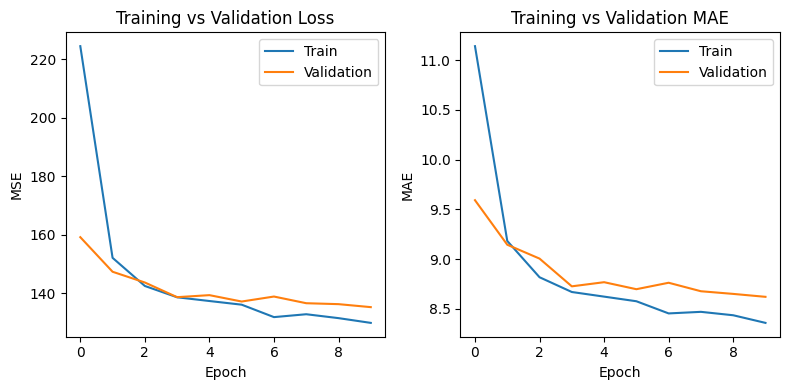

In [ ]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)

plt.plot(
    history_d2.history['loss'],
    label='Train'
)

plt.plot(
    history_d2.history['val_loss'],
    label='Validation'
)

plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Training vs Validation Loss')
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history_d2.history['mae'],
    label='Train'
)

plt.plot(
    history_d2.history['val_mae'],
    label='Validation'
)

plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.title('Training vs Validation MAE')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
base_model_d2.trainable = True

for layer in base_model_d2.layers[:-30]:
    layer.trainable = False

In [ ]:
model_d2.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss='mse',
    metrics=['mae']
)

In [ ]:
history_ft_d2 = model_d2.fit(
    train_ds,
    validation_data=test_ds,
    epochs=5,
    callbacks=callbacks_d2,
    verbose=1
)

Epoch 1/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 49s 102ms/step - loss: 147.5578 - mae: 8.9058 - val_loss: 143.5081 - val_mae: 8.7992 - learning_rate: 1.0000e-04
Epoch 2/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 16s 52ms/step - loss: 72.0404 - mae: 6.3271 - val_loss: 120.4932 - val_mae: 8.1948 - learning_rate: 1.0000e-04
Epoch 3/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 51ms/step - loss: 48.1768 - mae: 5.2147 - val_loss: 107.1407 - val_mae: 7.5783 - learning_rate: 1.0000e-04
Epoch 4/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 22s 55ms/step - loss: 35.6335 - mae: 4.5166 - val_loss: 105.5981 - val_mae: 7.4267 - learning_rate: 1.0000e-04
Epoch 5/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 19s 52ms/step - loss: 29.2061 - mae: 4.0629 - val_loss: 103.7697 - val_mae: 7.3949 - learning_rate: 1.0000e-04


In [ ]:
from math import sqrt

y_pred_d2 = np.concatenate([
    model_d2.predict(
        batch[0],
        verbose=0
    ).ravel()

    for batch in test_ds
])

mae_d2 = mean_absolute_error(
    y_test,
    y_pred_d2
)

rmse_d2 = sqrt(
    np.mean(
        (y_test - y_pred_d2) ** 2
    )
)

r2_d2 = r2_score(
    y_test,
    y_pred_d2
)

print(f"MAE  = {mae_d2:.2f} tahun")
print(f"RMSE = {rmse_d2:.2f} tahun")
print(f"R²   = {r2_d2:.3f}")

MAE  = 7.39 tahun
RMSE = 10.19 tahun
R²   = 0.739


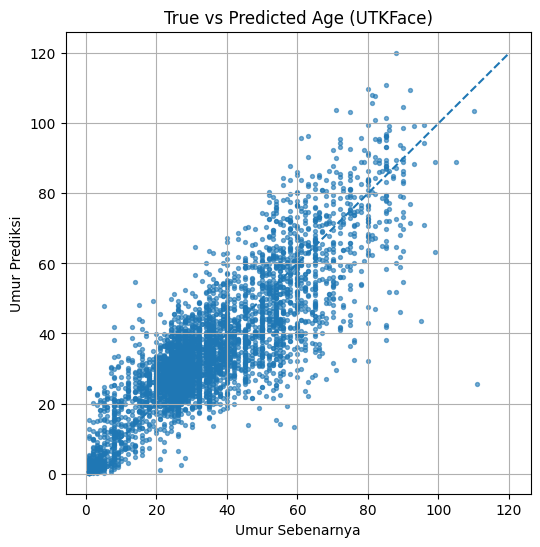

In [ ]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test,
    y_pred_d2,
    s=8,
    alpha=0.6
)

lims = [
    min(y_test.min(), y_pred_d2.min()),
    max(y_test.max(), y_pred_d2.max())
]

plt.plot(
    lims,
    lims,
    '--'
)

plt.xlabel("Umur Sebenarnya")
plt.ylabel("Umur Prediksi")
plt.title("True vs Predicted Age (UTKFace)")

plt.grid(True)

plt.show()

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving jokowi-manusia-biasa.jpg to jokowi-manusia-biasa (1).jpg


In [ ]:
from PIL import Image

nama_file = list(uploaded.keys())[0]

img = tf.io.read_file(nama_file)

img = tf.image.decode_jpeg(
    img,
    channels=3
)

img = tf.image.resize(
    img,
    (IMG_SIZE, IMG_SIZE)
)

img = img / 255.0

pred_age = model_d2.predict(
    tf.expand_dims(img, 0),
    verbose=0
).ravel()[0]

print(f"Prediksi umur: {pred_age:.2f} tahun")

Prediksi umur: 21.49 tahun


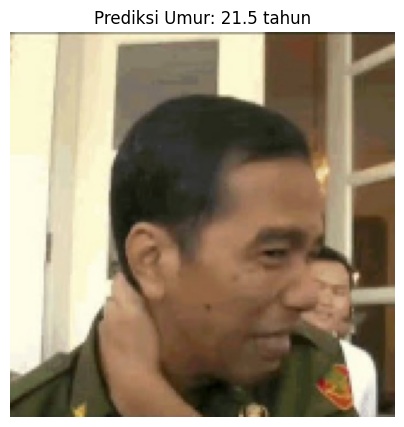

In [ ]:
plt.figure(figsize=(5, 5))

plt.imshow(img.numpy())

plt.title(
    f"Prediksi Umur: {pred_age:.1f} tahun"
)

plt.axis("off")

plt.show()

## D3 Pawpularity

In [ ]:
!kaggle competitions download -c petfinder-pawpularity-score -p /content -q

In [ ]:
!unzip -q /content/petfinder-pawpularity-score.zip -d /content/paw

print("Dataset Pawpularity berhasil diekstrak.")

Dataset Pawpularity berhasil diekstrak.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

from PIL import Image

df = pd.read_csv(
    '/content/paw/train.csv'
)

df['path'] = df['Id'].apply(
    lambda x: f"/content/paw/train/{x}.jpg"
)

print(df.head())
print("Jumlah data:", len(df))

                                 Id  Subject Focus  Eyes  Face  Near  Action  \
0  0007de18844b0dbbb5e1f607da0606e0              0     1     1     1       0   
1  0009c66b9439883ba2750fb825e1d7db              0     1     1     0       0   
2  0013fd999caf9a3efe1352ca1b0d937e              0     1     1     1       0   
3  0018df346ac9c1d8413cfcc888ca8246              0     1     1     1       0   
4  001dc955e10590d3ca4673f034feeef2              0     0     0     1       0   

   Accessory  Group  Collage  Human  Occlusion  Info  Blur  Pawpularity  \
0          0      1        0      0          0     0     0           63   
1          0      0        0      0          0     0     0           42   
2          0      0        0      1          1     0     0           28   
3          0      0        0      0          0     0     0           15   
4          0      1        0      0          0     0     0           72   

                                                path  
0  /content/p

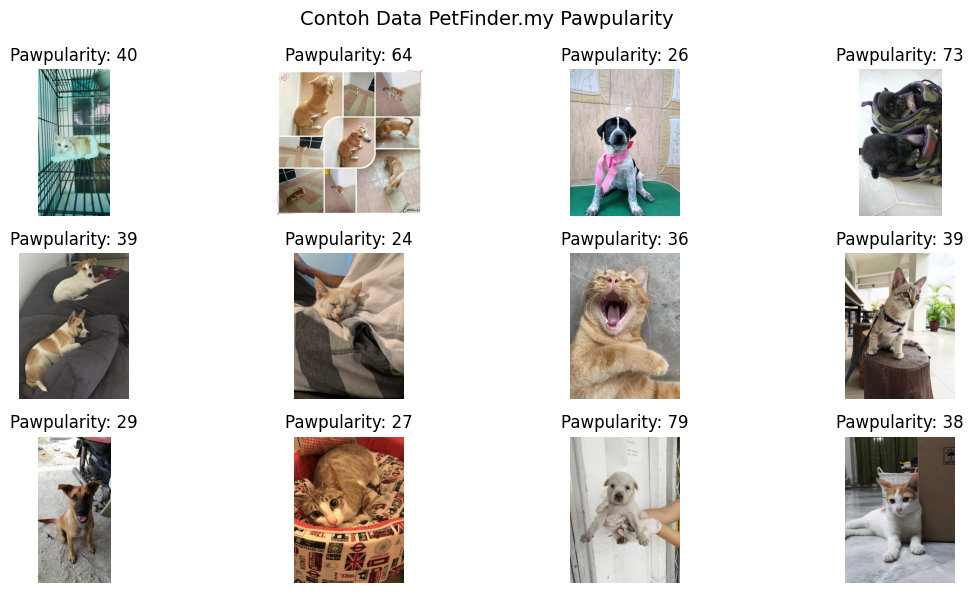

In [ ]:
plt.figure(figsize=(12, 6))

for i, row in enumerate(
    df.sample(12, random_state=42).itertuples()
):

    img = Image.open(row.path)

    plt.subplot(3, 4, i + 1)

    plt.imshow(img)

    plt.title(
        f"Pawpularity: {row.Pawpularity}"
    )

    plt.axis('off')

plt.suptitle(
    "Contoh Data PetFinder.my Pawpularity",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
import tensorflow as tf

IMG_SIZE_D3 = 224

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

print("Training :", len(train_df))
print("Validation:", len(val_df))

Training : 7929
Validation: 1983


In [ ]:
def load_image_d3(path, label):

    img = tf.io.read_file(path)

    img = tf.image.decode_jpeg(
        img,
        channels=3
    )

    img = tf.image.resize(
        img,
        (IMG_SIZE_D3, IMG_SIZE_D3)
    )

    img = tf.cast(
        img,
        tf.float32
    ) / 255.0

    return img, tf.cast(
        label,
        tf.float32
    )

In [ ]:
train_ds_d3 = tf.data.Dataset.from_tensor_slices(
    (
        train_df['path'].values,
        train_df['Pawpularity'].values
    )
).map(
    load_image_d3,
    num_parallel_calls=tf.data.AUTOTUNE
).shuffle(
    4096
).batch(
    64
).prefetch(
    tf.data.AUTOTUNE
)

In [ ]:
val_ds_d3 = tf.data.Dataset.from_tensor_slices(
    (
        val_df['path'].values,
        val_df['Pawpularity'].values
    )
).map(
    load_image_d3,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(
    64
).prefetch(
    tf.data.AUTOTUNE
)

print("Dataset D3 siap digunakan.")

Dataset D3 siap digunakan.


In [ ]:
from tensorflow.keras import layers

base_d3 = tf.keras.applications.EfficientNetB0(
    include_top=False,
    input_shape=(
        IMG_SIZE_D3,
        IMG_SIZE_D3,
        3
    ),
    weights='imagenet'
)

base_d3.trainable = False

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
inputs_d3 = tf.keras.Input(
    (IMG_SIZE_D3, IMG_SIZE_D3, 3)
)

x = tf.keras.applications.efficientnet.preprocess_input(
    inputs_d3 * 255.0
)

x = base_d3(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

x = layers.Dense(
    256,
    activation='relu'
)(x)

outputs_d3 = layers.Dense(1)(x)

model_d3 = tf.keras.Model(
    inputs_d3,
    outputs_d3
)

model_d3.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model_d3.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply_3 (Multiply)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,377,764 (16.70 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
callbacks_d3 = [

    tf.keras.callbacks.EarlyStopping(
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        patience=2,
        factor=0.5
    )
]

In [ ]:
history_d3 = model_d3.fit(
    train_ds_d3,
    validation_data=val_ds_d3,
    epochs=10,
    callbacks=callbacks_d3,
    verbose=1
)

Epoch 1/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 106s 486ms/step - loss: 609.0132 - mae: 18.0986 - val_loss: 479.4250 - val_mae: 16.0610 - learning_rate: 0.0010
Epoch 2/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 43s 224ms/step - loss: 421.8454 - mae: 15.1975 - val_loss: 437.2439 - val_mae: 15.0483 - learning_rate: 0.0010
Epoch 3/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 83s 246ms/step - loss: 390.7074 - mae: 14.6634 - val_loss: 403.4141 - val_mae: 14.9303 - learning_rate: 0.0010
Epoch 4/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 40s 212ms/step - loss: 377.9818 - mae: 14.4228 - val_loss: 390.5869 - val_mae: 14.8020 - learning_rate: 0.0010
Epoch 5/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 43s 222ms/step - loss: 365.1225 - mae: 14.2040 - val_loss: 380.2372 - val_mae: 14.3212 - learning_rate: 0.0010
Epoch 6/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 84s 242ms/step - loss: 352.2208 - mae: 13.9185 - val_loss: 375.6592 - val_mae: 14.4380 - learning_rate: 0.0010
Epoch 7/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 46s 248ms/step - loss: 344.4385 - mae: 13.7306 - val_

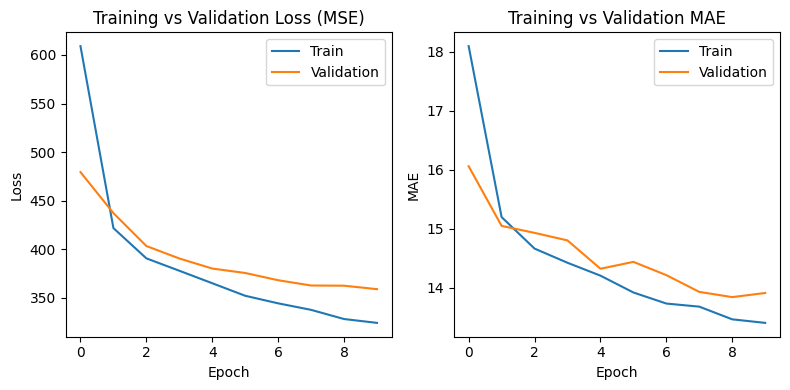

In [ ]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)

plt.plot(
    history_d3.history['loss'],
    label='Train'
)

plt.plot(
    history_d3.history['val_loss'],
    label='Validation'
)

plt.title(
    "Training vs Validation Loss (MSE)"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history_d3.history['mae'],
    label='Train'
)

plt.plot(
    history_d3.history['val_mae'],
    label='Validation'
)

plt.title(
    "Training vs Validation MAE"
)

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    r2_score
)

from math import sqrt

y_true_d3 = (
    val_df['Pawpularity']
    .values
    .astype(np.float32)
)

y_pred_d3 = np.concatenate([
    model_d3.predict(
        batch[0],
        verbose=0
    ).ravel()

    for batch in val_ds_d3
])

mae_d3 = mean_absolute_error(
    y_true_d3,
    y_pred_d3
)

rmse_d3 = sqrt(
    np.mean(
        (y_true_d3 - y_pred_d3) ** 2
    )
)

r2_d3 = r2_score(
    y_true_d3,
    y_pred_d3
)

print(f"MAE  = {mae_d3:.2f}")
print(f"RMSE = {rmse_d3:.2f}")
print(f"R²   = {r2_d3:.3f}")

MAE  = 13.91
RMSE = 18.95
R²   = 0.188


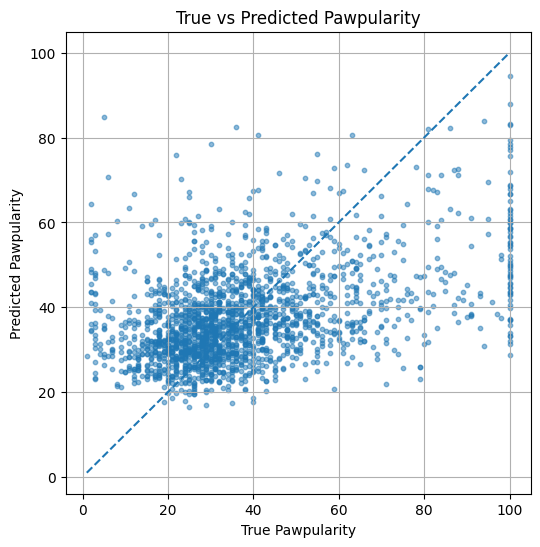

In [ ]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_true_d3,
    y_pred_d3,
    s=10,
    alpha=0.5
)

lims = [
    min(
        y_true_d3.min(),
        y_pred_d3.min()
    ),

    max(
        y_true_d3.max(),
        y_pred_d3.max()
    )
]

plt.plot(
    lims,
    lims,
    '--'
)

plt.xlabel("True Pawpularity")
plt.ylabel("Predicted Pawpularity")

plt.title(
    "True vs Predicted Pawpularity"
)

plt.grid(True)

plt.show()

In [ ]:
uploaded_d3 = files.upload()

Saving bakekok-kucing.jpg to bakekok-kucing.jpg


In [ ]:
nama_file_d3 = list(
    uploaded_d3.keys()
)[0]

img_d3 = tf.io.read_file(
    nama_file_d3
)

img_d3 = tf.image.decode_jpeg(
    img_d3,
    channels=3
)

img_d3 = tf.image.resize(
    img_d3,
    (
        IMG_SIZE_D3,
        IMG_SIZE_D3
    )
)

img_d3 = tf.cast(
    img_d3,
    tf.float32
) / 255.0

In [ ]:
pred_paw = model_d3.predict(
    tf.expand_dims(img_d3, 0),
    verbose=0
).ravel()[0]

print(
    f"Prediksi Pawpularity: {pred_paw:.2f}"
)

Prediksi Pawpularity: 32.46


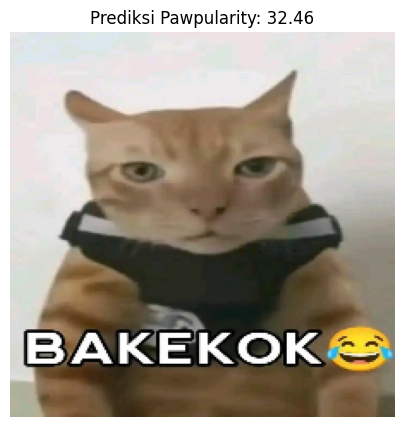

In [ ]:
plt.figure(figsize=(5, 5))

plt.imshow(
    img_d3.numpy()
)

plt.title(
    f"Prediksi Pawpularity: {pred_paw:.2f}"
)

plt.axis("off")

plt.show()